<a href="https://colab.research.google.com/github/Tharunnithish/Medical-chatbot/blob/main/Web_Intelligence_with_Python_Workshop_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Setup

In [ ]:
!pip -q install requests beautifulsoup4 pandas matplotlib

In [ ]:
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
print("Setup complete!")

Setup complete!


# 1. Web Intelligence: the big picture

Web Intelligence is collecting, processing, analyzing, and interpreting web information to support decisions.

**Industry use cases**
- E-commerce: competitor price monitoring
- Marketing: brand and customer feedback
- Recruitment: skills and job trend analysis
- Travel: comparing listings
- Product teams: feature requests and reviews

**Pipeline:** Discover source → Collect → Extract → Clean → Analyze → Interpret / decide

# 2. Regular Expressions (Regex)

Regex describes patterns in text. We don't need the exact value—we describe the shape of the value.

In [ ]:
text = "Python is popular. Python is used in AI. I am learning Python."
pattern = r"Python"
print(re.findall(pattern, text))

['Python', 'Python', 'Python']


## 2.1 Character classes

| Pattern | Meaning |
|---|---|
| `\d` | Digit |
| `\w` | Word character (letters, digits, underscore) |
| `\s` | Whitespace |
| `[0-9]` | Digit 0–9 |
| `[a-z]` | Lowercase |
| `[A-Z]` | Uppercase |
| `[6-9]` | Digit from 6 through 9 |
| `.` | Any character except newline by default |
| `\.` | Literal dot |

## 2.2 Quantifiers

| Pattern | Meaning |
|---|---|
| `+` | One or more |
| `*` | Zero or more |
| `?` | Zero or one / optional |
| `{3}` | Exactly 3 |
| `{2,5}` | Between 2 and 5 |

## 2.3 Build a 10-digit Indian mobile pattern

Text: `My number is 9876543210`

Reasoning:
- First digit is 6–9 → `[6-9]`
- Next nine digits are 0–9 → `[0-9]{9}`
- Combine → `[6-9][0-9]{9}`

In [ ]:
text = "Call 9876543210, 1234567890, or 8123456789."
pattern = r"[1-9][0-9]{9}"
print(re.findall(pattern, text))

['9876543210', '1234567890', '8123456789']


## 2.4 Build an email pattern

Example: `support@gmail.com` or `hr@company.in`

Simplified pieces:
- Username: ` [\w.-]+ `
- Literal @: `@`
- Domain: ` [\w.-]+ `
- Literal dot: `\\.`
- Extension: `\w+`

Combined: `[\w.-]+@[\w.-]+\.\w+`

This is a beginner extraction pattern, not a complete email validation standard.

In [ ]:
import re

text = "Contact support@gmail.com, careers@datacorp.in and hr@company.org"
pattern = r"[\w.-]+@[\w.-]+\.\w+"

print(re.findall(pattern, text))

['support@gmail.com', 'careers@datacorp.in', 'hr@company.org']


## 2.5 Build a price pattern

Text: `Laptop costs ₹75,999. Mouse costs ₹1,499. Keyboard costs ₹2299`

- Currency symbol: `₹`
- Digits or commas: `[\d,]`
- One or more: `+`

Combined: `₹[\d,]+`

In [ ]:
import re
text = "Laptop ₹75,999; Mouse ₹1,499; Keyboard ₹2299"
pattern = r"₹[\d,]+"
print(re.findall(pattern, text))

['₹75,999', '₹1,499', '₹2299']


## 2.6 Extract salary packages

Examples: `8 LPA`, `15 LPA`, `6.5 LPA`

Pattern parts:
- `\d+` → digits
- `\.?` → optional decimal point
- `\d*` → optional decimal digits
- `\s` → whitespace
- `LPA` → literal letters

Combined: `\d+\.?\d\sLPA`

In [ ]:
text = "Python Developer - 8 LPA; AI Engineer - 15 LPA; Data Analyst - 6.5 LPA; ML Engineer - 18 LPA"
pattern = r"\d+\.?\d*\sLPA"
print(re.findall(pattern, text))

['8 LPA', '15 LPA', '6.5 LPA', '18 LPA']


# 2.7 Date and URL patterns

In [ ]:
text = "Events: 19-11-2026, 2026/11/19. Visit https://example.com/jobs?id=42"
date_pattern = r"\d{2}-\d{2}-\d{4}"
url_pattern = r"https?:/\S+"
print("Dates:", re.findall(date_pattern, text))
print("URLs:", re.findall(url_pattern, text))

Dates: ['19-11-2026']
URLs: ['https://example.com/jobs?id=42']


## 2.8 Student activity — attempt before solution

From the text below, extract:
1. Emails
2. 10-digit Indian mobile numbers beginning 6–9
3. Salaries in LPA
4. Dates in DD-MM-YYYY

Fill the patterns in the starter cell. Then run the instructor solution.

In [ ]:
student_text = '''
Recruiter: jobs@company.in
Phone: 9876543210
Candidate contact: 8123456789
Invalid-looking example: 1234567890
Salary for Data Analyst: 6.5 LPA
Salary for AI Engineer: 18 LPA
Interview dates: 25-11-2026 and 03-12-2026
Another email: hiring.team@example.org
'''


In [ ]:
import re
student_text = '''
Recruiter: jobs@company.in
Phone: 9876543210
Candidate contact: 8123456789
Invalid-looking example: 1234567890
Salary for Data Analyst: 6.5 LPA
Salary for AI Engineer: 18 LPA
Interview dates: 25-11-2026 and 03-12-2026
Another email: hiring.team@example.org
'''
email_pattern = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
mobile_pattern = r'[6-9]\d{9}'
salary_pattern = r'\d+(?:\.\d+)?\s*LPA'
date_pattern = r'\b\d{2}-\d{2}-\d{4}\b'

emails = re.findall(email_pattern, student_text)
mobiles = re.findall(mobile_pattern, student_text)
salaries = re.findall(salary_pattern, student_text)
dates = re.findall(date_pattern, student_text)

print("Emails:", emails)
print("Mobile Numbers:", mobiles)
print("Salaries:", salaries)
print("Dates:", dates)

Emails: ['jobs@company.in', 'hiring.team@example.org']
Mobile Numbers: ['9876543210', '8123456789']
Salaries: ['6.5 LPA', '18 LPA']
Dates: ['25-11-2026', '03-12-2026']


### Instructor solution

In [ ]:
email_pattern = r"[\w.-]+@[\w.-]+\.\w+"
phone_pattern = r"(?<!\d)[6-9]\d{9}(?!\d)"
salary_pattern = r"\d+.?\d*\sLPA"
date_pattern = r"\d{2}-\d{2}-\d{4}"

print("Emails:", re.findall(email_pattern, student_text))
print("Phones:", re.findall(phone_pattern, student_text))
print("Salaries:", re.findall(salary_pattern, student_text))
print("Dates:", re.findall(date_pattern, student_text))

Emails: ['jobs@company.in', 'hiring.team@example.org']
Phones: ['9876543210', '8123456789']
Salaries: ['6.5 LPA', '18 LPA']
Dates: ['25-11-2026', '03-12-2026']


**Regex recap:** Start with the raw text → identify what you need → identify fixed/variable parts → choose character classes → add quantifiers → combine and test. Regex finds shapes, not necessarily valid real-world values.

## 3.1 Content Mining toy example: tokenize reviews

In [ ]:
reviews = [
    "The battery life is excellent and display is beautiful",
    "Poor build quality and terrible customer service",
    "Fast performance but battery is disappointing",
    "Great value and excellent performance"
]
for review in reviews:
    words = re.findall(r"\w+", review.lower())
    print(words)

['the', 'battery', 'life', 'is', 'excellent', 'and', 'display', 'is', 'beautiful']
['poor', 'build', 'quality', 'and', 'terrible', 'customer', 'service']
['fast', 'performance', 'but', 'battery', 'is', 'disappointing']
['great', 'value', 'and', 'excellent', 'performance']


## 3.2 Structure Mining: link relationships (toy dataset)

In [ ]:
links = [
    ("Home", "Products"), ("Home", "Blog"),
    ("Products", "Product_A"), ("Products", "Product_B"),
    ("Blog", "Article_1"), ("Article_1", "Products")
]
link_df = pd.DataFrame(links, columns=["source_page", "target_page"])
display(link_df)
print("Outgoing links per page:")
display(link_df["source_page"].value_counts())

,source_page,target_page
0,Home,Products
1,Home,Blog
2,Products,Product_A
3,Products,Product_B
4,Blog,Article_1
5,Article_1,Products


Outgoing links per page:


,count
source_page,
Home,2
Products,2
Blog,1
Article_1,1


## 3.3 Usage Mining: simulated clickstream

In [ ]:
clickstream = pd.DataFrame({
    "session_id": ["S1","S1","S1","S2","S2","S3","S3","S3"],
    "page": ["Home","Product","Cart","Home","Product","Home","Product","Checkout"],
    "event": ["view","view","abandon","view","view","view","view","purchase"]
})
display(clickstream)
print("Events:")
display(clickstream["event"].value_counts())
print("Pages:")
display(clickstream["page"].value_counts())

,session_id,page,event
0,S1,Home,view
1,S1,Product,view
2,S1,Cart,abandon
3,S2,Home,view
4,S2,Product,view
5,S3,Home,view
6,S3,Product,view
7,S3,Checkout,purchase


Events:


,count
event,
view,6
abandon,1
purchase,1


Pages:


,count
page,
Home,3
Product,3
Cart,1
Checkout,1


# 4. Web Scraping fundamentals

Web scraping is automated retrieval of a webpage and extraction of selected information.

**Flow**
1. Python sends an HTTP request
2. Server returns HTML
3. BeautifulSoup parses HTML
4. CSS selectors target elements
5. We extract text or attributes
6. Store structured data

Tools: `requests` (HTTP), `BeautifulSoup` (HTML parsing), `re` (patterns), `pandas` (data analysis).

In [ ]:
sample_html = (
    '<div class="product">'
    '<h2 class="title">Wireless Headphones</h2>'
    '<span class="price">₹2,499</span>'
    '<p class="rating">4.5 out of 5</p>'
    '</div>'
)
print(sample_html)

<div class="product"><h2 class="title">Wireless Headphones</h2><span class="price">₹2,499</span><p class="rating">4.5 out of 5</p></div>


## 4.1 Parse sample HTML (offline)

In [ ]:
sample_soup = BeautifulSoup(sample_html, "html.parser")
print("Title:", sample_soup.select_one(".title").get_text(strip=True))
print("Price:", sample_soup.select_one(".price").get_text(strip=True))
print("Rating:", sample_soup.select_one(".rating").get_text(strip=True))

Title: Wireless Headphones
Price: ₹2,499
Rating: 4.5 out of 5


## 4.2 CSS selectors quick reference

| Selector | Meaning |
|---|---|
| `h2` | All h2 elements |
| `.price` | Class named price |
| `#main` | ID named main |
| `div.product` | div with class product |
| `div.product h2` | h2 inside product div |

`select()` finds all matches; `select_one()` returns the first match or `None`.

# 5. Live scraping demo — Books to Scrape

This educational catalog is intended for scraping practice. The catalog shows book titles, prices (in pounds), availability, and rating categories.

## 5.1 Request a webpage

In [ ]:
url = "https://books.toscrape.com/"
headers = {"User-Agent": "Mozilla/5.0 (compatible; WorkshopDemo/1.0)"}
response = requests.get(url, headers=headers, timeout=20)
print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print(response.text[:500])

Status: 200
Content type: text/html
<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" /


If request fails: check connectivity and rerun once. `200` typically indicates success, `403` denied, `404` not found, `429` rate limit. If unavailable, use the fallback HTML cells below. Do not hammer a site with repeated requests.

## 5.2 Parse returned HTML

In [ ]:
soup = BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.get_text(strip=True) if soup.title else "No title")
print("Product cards found:", len(soup.select(".product_pod")))

Page title: All products | Books to Scrape - Sandbox
Product cards found: 20


## 5.3 Inspect one card before writing selectors (a good scraping habit)

In [13]:
# Ensure 'soup' is defined before trying to inspect a card
try:
    soup
except NameError:
    import requests
    from bs4 import BeautifulSoup
    url = "https://books.toscrape.com/"
    headers = {"User-Agent": "Mozilla/5.0 (compatible; WorkshopDemo/1.0)"}
    response = requests.get(url, headers=headers, timeout=20)
    soup = BeautifulSoup(response.text, "html.parser")

first_book = soup.select_one(".product_pod")
print(first_book.prettify()[:2500] if first_book else "No product card found")

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



## 5.4 Extract fields from product cards

Selectors used:
- Card: `.product_pod`
- Title: `h3 a` → `title` attribute
- Price: `.price_color` → text
- Rating: `.star-rating` → CSS class
- Availability: `.availability` → text

In [ ]:
def extract_books_from_page(page_soup):
    records = []
    for book in page_soup.select(".product_pod"):
        title_tag = book.select_one("h3 a")
        price_tag = book.select_one(".price_color")
        rating_tag = book.select_one(".star-rating")
        availability_tag = book.select_one(".availability")
        if not title_tag or not price_tag:
            continue
        title = title_tag.get("title", title_tag.get_text(strip=True))
        price_text = price_tag.get_text(strip=True)
        rating = rating_tag.get("class")[-1] if rating_tag and rating_tag.get("class") else None
        availability = availability_tag.get_text(" ", strip=True) if availability_tag else None
        records.append({
            "title": title,
            "price_text": price_text,
            "rating": rating,
            "availability": availability
        })
    return records

books_data = extract_books_from_page(soup)
print("Records:", len(books_data))
books_data[:3]

Records: 20


[{'title': 'A Light in the Attic',
  'price_text': 'Â£51.77',
  'rating': 'Three',
  'availability': 'In stock'},
 {'title': 'Tipping the Velvet',
  'price_text': 'Â£53.74',
  'rating': 'One',
  'availability': 'In stock'},
 {'title': 'Soumission',
  'price_text': 'Â£50.10',
  'rating': 'One',
  'availability': 'In stock'}]

## 5.5 Create a DataFrame

In [ ]:
books_df = pd.DataFrame(books_data)
display(books_df.head())
print("Rows:", len(books_df), "| Columns:", books_df.columns.tolist())

,title,price_text,rating,availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


Rows: 20 | Columns: ['title', 'price_text', 'rating', 'availability']


## Where does a price such as `£51.77` come from?

It is **read from the website's HTML**—we do not type it manually. In the extraction function, `price_tag.get_text(strip=True)` returns the text inside the price element, whatever the page currently shows. The actual scraped prices can vary by product and page.

# 6. Mini project — Product Catalog Intelligence

## Business scenario
An online retailer wants to understand the catalog:
- How many products did we collect?
- What is the average / min / max price?
- Which products are cheapest or most expensive?
- Which rating categories are common?
- What does the price distribution look like?

We will clean the displayed price string and analyze it.

In [15]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

# Ensure books_data is defined
try:
    books_data
except NameError:
    # Define the extraction function if missing
    def extract_books_from_page(page_soup):
        records = []
        for book in page_soup.select(".product_pod"):
            title_tag = book.select_one("h3 a")
            price_tag = book.select_one(".price_color")
            rating_tag = book.select_one(".star-rating")
            availability_tag = book.select_one(".availability")
            if not title_tag or not price_tag:
                continue
            title = title_tag.get("title", title_tag.get_text(strip=True))
            price_text = price_tag.get_text(strip=True)
            rating = rating_tag.get("class")[-1] if rating_tag and rating_tag.get("class") else None
            availability = availability_tag.get_text(" ", strip=True) if availability_tag else None
            records.append({
                "title": title,
                "price_text": price_text,
                "rating": rating,
                "availability": availability
            })
        return records

    # Re-fetch page and create books_data
    url = "https://books.toscrape.com/"
    headers = {"User-Agent": "Mozilla/5.0 (compatible; WorkshopDemo/1.0)"}
    response = requests.get(url, headers=headers, timeout=20)
    soup = BeautifulSoup(response.text, "html.parser")
    books_data = extract_books_from_page(soup)

# Ensure analysis_df is properly initialized and cleaned
books_df = pd.DataFrame(books_data)
analysis_df = books_df.copy()

# Clean price strings using regular expressions to convert them to float
analysis_df["price"] = (
    analysis_df["price_text"]
    .str.replace(r"[^\d.]", "", regex=True)
    .astype(float)
)
display(analysis_df[["title", "price_text", "price", "rating"]].head())

,title,price_text,price,rating
0,A Light in the Attic,Â£51.77,51.77,Three
1,Tipping the Velvet,Â£53.74,53.74,One
2,Soumission,Â£50.10,50.10,One
3,Sharp Objects,Â£47.82,47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,54.23,Five


## 6.1 Summary statistics

In [ ]:
print("Products:", len(analysis_df))
print("Mean price:", round(analysis_df["price"].mean(), 2))
print("Min price:", analysis_df["price"].min())
print("Max price:", analysis_df["price"].max())
print("Median price:", analysis_df["price"].median())

Products: 20
Mean price: 38.05
Min price: 13.99
Max price: 57.25
Median price: 41.38


## 6.2 Five cheapest products

In [16]:
display(analysis_df.sort_values("price")[["title", "price_text", "price", "rating"]].head(5))

,title,price_text,price,rating
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Â£13.99,13.99,Two
12,Set Me Free,Â£17.46,17.46,Five
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,17.93,Three
11,Shakespeare's Sonnets,Â£20.66,20.66,Four
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,22.60,Four


## 6.3 Five most expensive products

In [ ]:
display(analysis_df.sort_values("price", ascending=False)[["title", "price_text", "price", "rating"]].head(5))

,title,price_text,price,rating
15,Our Band Could Be Your Life: Scenes from the A...,Â£57.25,57.25,Three
4,Sapiens: A Brief History of Humankind,Â£54.23,54.23,Five
1,Tipping the Velvet,Â£53.74,53.74,One
13,Scott Pilgrim's Precious Little Life (Scott Pi...,Â£52.29,52.29,Five
9,The Black Maria,Â£52.15,52.15,One


## 6.4 Rating distribution

,count
rating,
One,6
Five,4
Four,4
Three,3
Two,3


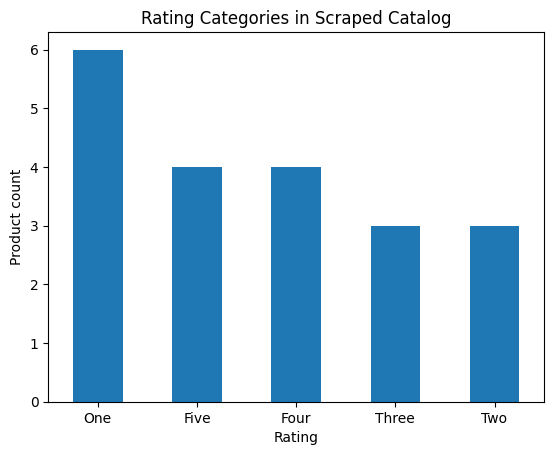

In [ ]:
rating_counts = analysis_df["rating"].value_counts()
display(rating_counts)
rating_counts.plot(kind="bar")
plt.title("Rating Categories in Scraped Catalog")
plt.xlabel("Rating")
plt.ylabel("Product count")
plt.xticks(rotation=0)
plt.show()

## 6.5 Price distribution

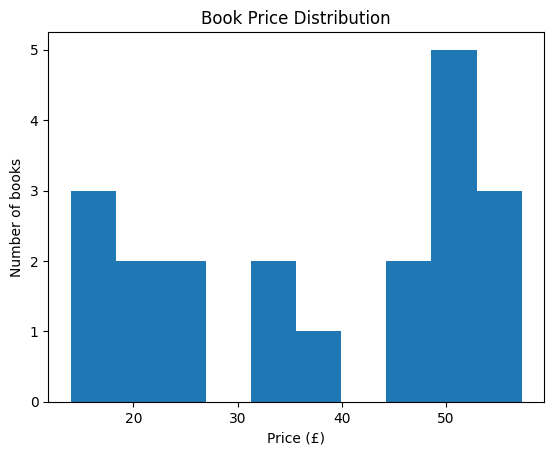

In [ ]:
analysis_df["price"].plot(kind="hist", bins=10)
plt.title("Book Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.show()

## 6.6 Export CSV

In [ ]:
analysis_df.to_csv("books_catalog_intelligence.csv", index=False)
print("Saved books_catalog_intelligence.csv")

Saved books_catalog_intelligence.csv


In Google Colab, download the CSV using the next cell, or use the Files sidebar.

## 6.7 Interpret the output

Fill in using your own results:
- We collected ___ products.
- Average listed price was ___.
- Cheapest item was ___.
- Most expensive item was ___.
- Most common rating was ___.
- The histogram suggests ___.

**Industry lesson:** printing numbers is analysis; explaining what those numbers mean is intelligence.

# 7. Scrape multiple pages

This is optional if the class is ahead of schedule. We limit the page count and add a one-second delay between requests.

In [ ]:
from urllib.parse import urljoin
import time

def scrape_catalog_pages(start_url, max_pages=3):
    collected = []
    current_url = start_url
    for page_num in range(max_pages):
        print(f"Fetching page {page_num + 1}: {current_url}")
        page_response = requests.get(current_url, headers=headers, timeout=20)
        page_response.raise_for_status()
        page_soup = BeautifulSoup(page_response.text, "html.parser")
        collected.extend(extract_books_from_page(page_soup))
        next_link = page_soup.select_one("li.next a")
        if not next_link:
            print("No next page link; stopping.")
            break
        current_url = urljoin(current_url, next_link["href"])
        time.sleep(1)
    return collected

#Uncomment to run:
multi_page_data = scrape_catalog_pages(url, max_pages=3)
multi_page_df = pd.DataFrame(multi_page_data)
print("Collected rows:", len(multi_page_df))
display(multi_page_df.head())

Fetching page 1: https://books.toscrape.com/
Fetching page 2: https://books.toscrape.com/catalogue/page-2.html
Fetching page 3: https://books.toscrape.com/catalogue/page-3.html
Collected rows: 60


,title,price_text,rating,availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


# 8. Mini-challenge — Product Intelligence

Using `analysis_df`:
1. Calculate the average price.
2. Display the 3 cheapest products.
3. Display the 3 most expensive products.
4. Find the most common rating.
5. Plot a price histogram.
6. Filter products priced above the average.
7. Save your results to CSV.

**Bonus:** Count products by rating, find in-stock products, and write two business insights in plain English.

Average price: 38.05
3 cheapest products:


,title,price,rating
10,"Starving Hearts (Triangular Trade Trilogy, #1)",13.99,Two
12,Set Me Free,17.46,Five
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three


3 most expensive products:


,title,price,rating
15,Our Band Could Be Your Life: Scenes from the A...,57.25,Three
4,Sapiens: A Brief History of Humankind,54.23,Five
1,Tipping the Velvet,53.74,One


Most common rating: One


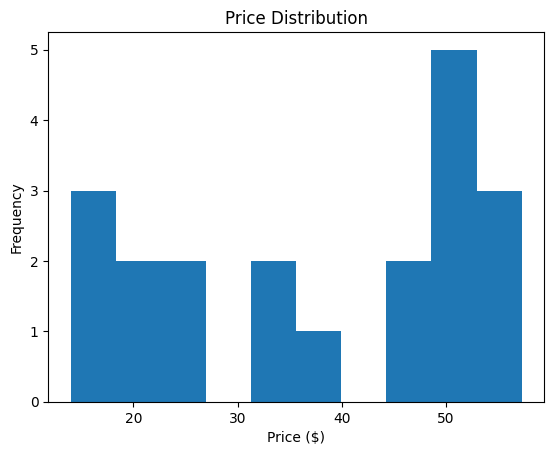

Products priced above average:


,title,price,rating
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five
9,The Black Maria,52.15,One
13,Scott Pilgrim's Precious Little Life (Scott Pi...,52.29,Five
15,Our Band Could Be Your Life: Scenes from the A...,57.25,Three
18,Libertarianism for Beginners,51.33,Two
19,It's Only the Himalayas,45.17,Two


In [19]:
import matplotlib.pyplot as plt

price_avg = analysis_df["price"].mean()
print("Average price:", round(price_avg, 2))

three_cheapest = analysis_df.nsmallest(3, "price")[["title", "price", "rating"]]
print("3 cheapest products:")
display(three_cheapest)

three_exp = analysis_df.nlargest(3, "price")[["title", "price", "rating"]]
print("3 most expensive products:")
display(three_exp)

most_cmn_r = analysis_df["rating"].value_counts().idxmax()
print("Most common rating:", most_cmn_r)

histogram = analysis_df["price"].plot(kind="hist", bins=10)
plt.title("Price Distribution")
plt.xlabel("Price ($)")
plt.show()

above_avg = analysis_df[analysis_df["price"] > price_avg][["title", "price", "rating"]]
print("Products priced above average:")
display(above_avg)

## Challenge solution

Average: 38.05
3 cheapest:


,title,price,rating
10,"Starving Hearts (Triangular Trade Trilogy, #1)",13.99,Two
12,Set Me Free,17.46,Five
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three


3 most expensive:


,title,price,rating
15,Our Band Could Be Your Life: Scenes from the A...,57.25,Three
4,Sapiens: A Brief History of Humankind,54.23,Five
1,Tipping the Velvet,53.74,One


Most common rating: One


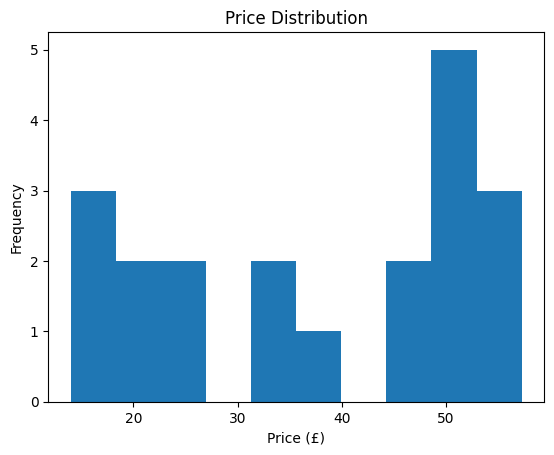

Above-average price products:


,title,price,rating
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five


In [ ]:
avg = analysis_df["price"].mean()
print("Average:", round(avg, 2))

print("3 cheapest:")
display(analysis_df.nsmallest(3, "price")[["title", "price", "rating"]])

print("3 most expensive:")
display(analysis_df.nlargest(3, "price")[["title", "price", "rating"]])

print("Most common rating:", analysis_df["rating"].value_counts().idxmax())

analysis_df["price"].plot(kind="hist", bins=10)
plt.title("Price Distribution")
plt.xlabel("Price (£)")
plt.show()

print("Above-average price products:")
display(analysis_df[analysis_df["price"] > avg][["title", "price", "rating"]].head())